# Object and Face Detection in Images using YOLO

- `YOLO`, which stands for `"You Only Look Once"` is a popular family of real-time computer vision models primarily used for object detection. 
- Originally developed by Joseph Redmon in 2015, it revolutionized computer vision by treating object detection as a single regression problem rather than a multi-stage classification task. 

- Instead of searching for areas of interest and then classifying them separately, `YOLO` passes an entire image through a `single neural network` just once to predict both `where objects are (bounding boxes)` and what `they are (class labels)` simultaneously.

<img src="images/yolo_models.png" width="800" height="500">

YOLO models can be automatically downloaded from ultralytics with their standard naming convention: `[family][version][size]-[task].pt` for example 
- `yolo26m.pt")` => Yolo Family, version 26, medium size.

- `yolo26s-seg.pt")` => Yolo Family, version 26, nano size, seg = for segmentation.

- `yolo26s-face.pt")` => Yolo Family, version 26, nano size, face = for face detection.

The model file will automatically the first time you run code.
Go to [docs.ultralytics.com/models](https://docs.ultralytics.com/models) to see the list of all the available models.



### 1. Image classification with Yolo
- Image classification is the simplest of the supported tasks and involves classifying an entire image into one of a set of predefined classes.

- The output of an image classifier is a single class label and a confidence score. 

- Image classification is useful when you need to know only what class an image belongs to and don't need to know where objects of that class are located or what their exact shape is.

In [ ]:
# Load libraries and yolo models
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO


0: 224x224 limousine 0.29, minivan 0.18, car_wheel 0.15, beach_wagon 0.08, police_van 0.06, 16.4ms
Speed: 7.0ms preprocess, 16.4ms inference, 0.0ms postprocess per image at shape (1, 3, 224, 224)
Top Prediction: Limousine (Confidence: 0.29)


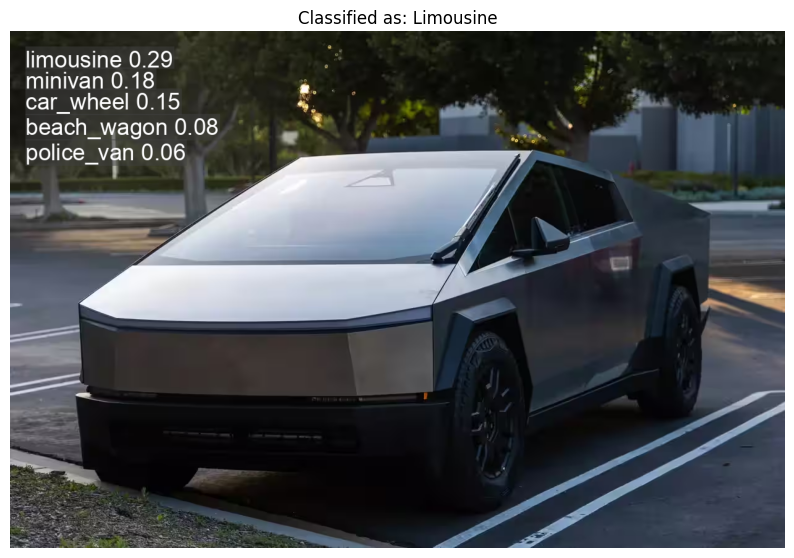

In [47]:

# 1. Load the classification model 
# (The '-cls' suffix indicates it is an image classification model)
classify_model = YOLO("yolo_models/yolo26n-cls.pt")

# 2. Read the demo image
image = cv2.imread("images/demo5.jpg")

# 3. Run image classification
results = classify_model(image)

# 4. Extract the classification probabilities and labels natively
probs = results[0].probs

top1_id = probs.top1                  # Get the class ID with the highest probability
top1_conf = float(probs.top1conf)     # Get the confidence score
top1_name = results[0].names[top1_id] # Map the ID back to the human-readable class name

print(f"Top Prediction: {top1_name.capitalize()} (Confidence: {top1_conf:.2f})")

# 5. Use the built-in plot() method to stamp the prediction text onto the image
processed_image = results[0].plot()

# 6. Convert BGR (OpenCV) to RGB (Matplotlib) for correct colors
processed_image_rgb = cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGB)

# 7. Display the result
plt.figure(figsize=(10, 8))
plt.imshow(processed_image_rgb)
plt.title(f"Classified as: {top1_name.capitalize()}")
plt.axis('off')
plt.show()

### 2. Detect Objects with Official YOLO Model

The following code will detect different objects in images such as: person, cat, laptop, cup, etc.

In [50]:
import cv2
from ultralytics import YOLO
import matplotlib.pyplot as plt
import os

# download and/or load YOLO model
os.makedirs("yolo_models", exist_ok=True)
model = YOLO("yolo_models/yolo26n.pt")


##### Load a demo image and use yolo model to detect objects
# Load a demo image
image = cv2.imread("images/demo0.jpg")

# Convert from BGR to RGB (for display only)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# run the yolo model to detect objects
detection_result = model(image)


0: 448x640 1 cup, 1 laptop, 1 mouse, 69.9ms
Speed: 2.0ms preprocess, 69.9ms inference, 0.8ms postprocess per image at shape (1, 3, 448, 640)


#### Use this native code to get the bounding boxes, class names, and confidence 

#### Or use this `plot()` method...

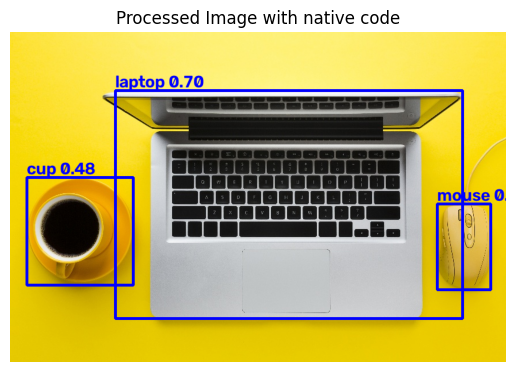

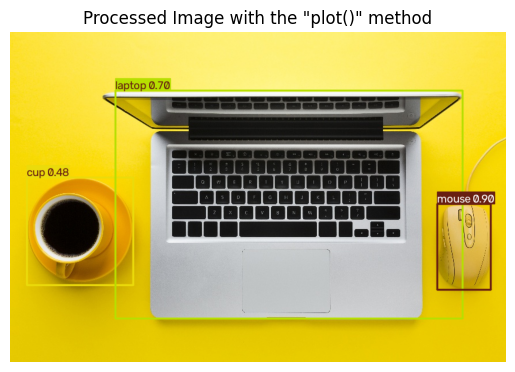

In [51]:
#################### Use this native code to get the bounding boxes, class names, and confidence ####################
# Get the bounding boxes of the detected objects
boxes = detection_result[0].boxes

# Get the class names of the detected objects
class_names = model.names # get all the class names
detected_objects = [class_names[int(box.cls[0])] for box in boxes] 

# put the bounding boxes, class names, and confidence on the image
processed_image1 = image.copy()
for box, cls in zip(boxes, detected_objects):
    # Get coordinates
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
    
    # Get confidence score and format it to 2 decimal places
    confidence = float(box.conf[0])
    label = f"{cls} {confidence:.2f}"
    
    # Draw rectangle
    cv2.rectangle(processed_image1, (x1, y1), (x2, y2), (0, 0, 255), 3)
    
    # Draw text (shifted slightly up by 10 pixels for better visibility)
    cv2.putText(processed_image1, label, (x1, y1 - 5), 
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)


            
#################### Or use this plot() method... ####################
# plot the bounding boxes on the image
processed_image2 = detection_result[0].plot()


# Show image with this...
plt.imshow(processed_image1)
plt.title('Processed Image with native code')
plt.axis('off')
#plt.figure(figsize=(1000, 1000)) # set the figure size
plt.show()

# Show image with this...
plt.imshow(processed_image2)
plt.title('Processed Image with the "plot()" method')
plt.axis('off')
#plt.figure(figsize=(1000, 1000)) # set the figure size
plt.show()


### 3. Detect Faces with Community YOLO-Face Model

For this you'll need to download `yolov8m-face.pt` from:
https://github.com/akanametov/yolo-face



0: 448x640 1 face, 60.0ms
Speed: 3.0ms preprocess, 60.0ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)


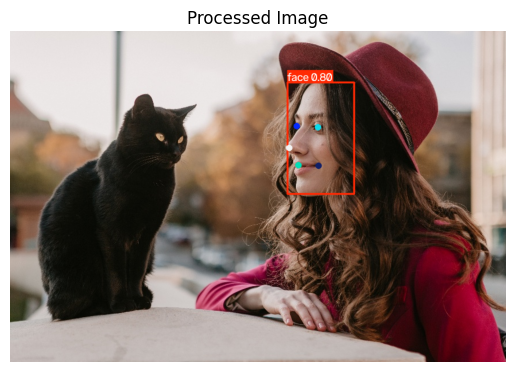

In [42]:
#import cv2
#from ultralytics import YOLO

# load YOLO-Face model from local folder
face_model = YOLO("yolo_models/yolo26n-face.pt")

# send a demo image to the model
image = cv2.imread("images/demo1.jpg")

# Convert from BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# run the yolo model to detect objects
face_detection_result = face_model(image)

# display the face detection results
processed_image = face_detection_result[0].plot()


# Show image with this...
plt.imshow(processed_image)
plt.title('Processed Image')
plt.axis('off')
#plt.figure(figsize=(1000, 1000)) # set the figure size
plt.show()


# Or use this...
#cv2.imshow("my window", processed_image)
#cv2.moveWindow("my window", 1800, 200)
#cv2.waitKey(5000) # display window for 5 seconds
#cv2.destroyAllWindows()

### 4. Detect Objects and Faces, Combining Two YOLO Models
The following code combines both models, working on the same image.


0: 448x640 1 person, 1 cat, 1 dining table, 65.9ms
Speed: 7.7ms preprocess, 65.9ms inference, 0.8ms postprocess per image at shape (1, 3, 448, 640)

0: 448x640 1 face, 57.2ms
Speed: 6.2ms preprocess, 57.2ms inference, 0.9ms postprocess per image at shape (1, 3, 448, 640)


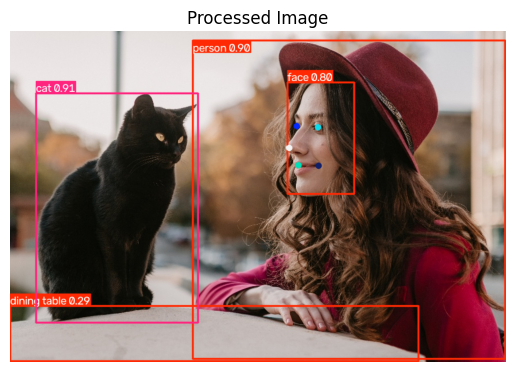

In [43]:
#import cv2
#from ultralytics import YOLO

# load both models
model = YOLO("yolo_models/yolo26n.pt")
face_model = YOLO("yolo_models/yolo26n-face.pt")

# send the same demo image to both models
image = cv2.imread("images/demo1.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# detect objects and faces
result = model(image)
face_result = face_model(image)

# put the combined detection results in the same window
cat_person = result[0].plot()
cat_person_face = face_result[0].plot(img=cat_person)


# Show image with this...
plt.imshow(cat_person_face)
plt.title('Processed Image')
plt.axis('off')
#plt.figure(figsize=(1000, 1000)) # set the figure size
plt.show()


### 5. Instance Segmentation with Yolo
- Instance segmentation goes a step further than object detection and involves identifying individual objects in an image and segmenting them from the rest of the image.

- The output of an instance segmentation model is a set of masks or contours that outline each object in the image, along with class labels and confidence scores for each object. 

- Instance segmentation is useful when you need to know not only where objects are in an image, but also what their exact shape is.

The following code shows how to implement object segmentation in an image.


0: 448x640 1 person, 2 bicycles, 6 cars, 83.1ms
Speed: 2.4ms preprocess, 83.1ms inference, 9.1ms postprocess per image at shape (1, 3, 448, 640)


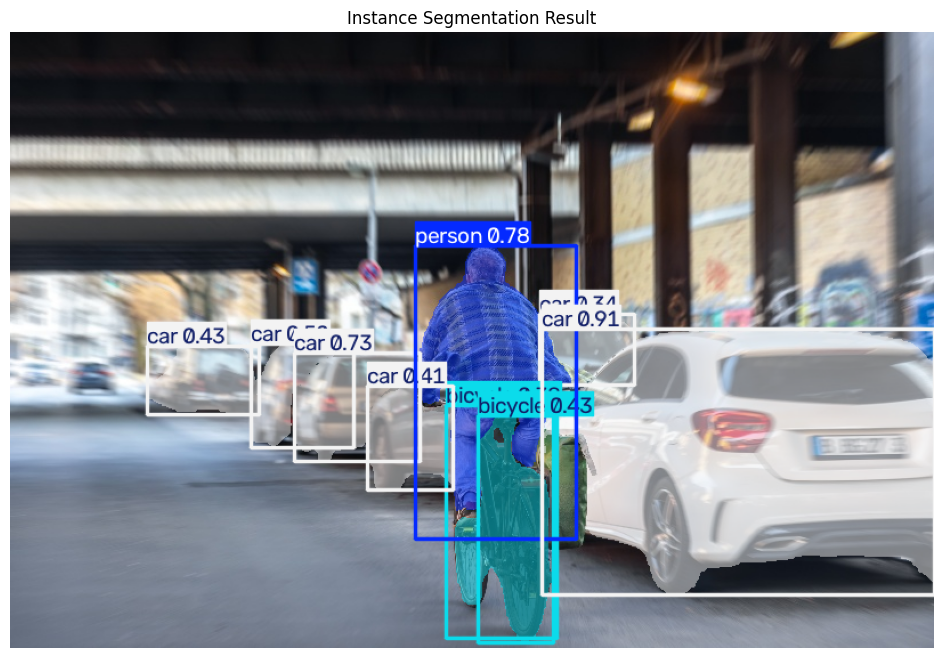

Successfully detected 9 segment masks!


In [39]:

import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load the segmentation model
# (It will automatically download if it is not already in your folder)
seg_model = YOLO("yolo_models/yolo26n-seg.pt")

# 2. Read the demo image
image = cv2.imread("images/demo2.jpg")

# 3. Run instance segmentation
# The model detects objects AND calculates their pixel masks
results = seg_model(image)

# 4. Use the built-in plot() method to draw boxes, labels, AND colored masks
processed_image = results[0].plot()

# 5. Convert BGR (OpenCV) to RGB (Matplotlib) for correct colors
processed_image_rgb = cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGB)

# 6. Display the result
plt.figure(figsize=(12, 8))
plt.imshow(processed_image_rgb)
plt.title('Instance Segmentation Result')
plt.axis('off')
plt.show()

# ---------------------------------------------------------
# NATIVE EXTRACTION TIP
# If you want to extract the raw mask data for their own calculations:
if results[0].masks is not None:
    print(f"Successfully detected {len(results[0].masks)} segment masks!")
    
    # results[0].masks.xy contains a list of polygon coordinates for each object's outline
    # results[0].masks.data contains the raw binary tensor masks (0s and 1s)
else:
    print("No objects were segmented in this image.")

#### 6. Semantic segmentation with Yolo
- Semantic segmentation assigns a class label to every pixel in an image, producing a dense class map that covers the entire scene. 

- Unlike `instance segmentation`, which separates individual objects, `semantic segmentation` groups all pixels of the same class together regardless of how many distinct objects are present.


0: 1024x768 147.1ms
Speed: 7.1ms preprocess, 147.1ms inference, 211.6ms postprocess per image at shape (1, 3, 1024, 768)


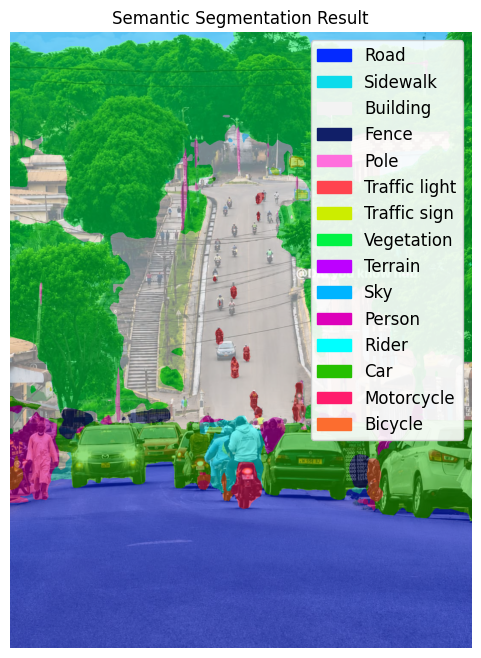

Successfully generated semantic mask!


In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ultralytics import YOLO
from ultralytics.utils.plotting import colors 

# 1. Load the semantic segmentation model 
sem_model = YOLO("yolo_models/yolo26n-sem.pt")

# 2. Read the demo image
image = cv2.imread("images/demo_ndere2.png")

# 3. Run semantic segmentation
results = sem_model(image)

# 4. Draw the dense class map 
processed_image = results[0].plot()

# 5. Convert BGR (OpenCV) to RGB (Matplotlib)
processed_image_rgb = cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGB)

# 6. Set up the Matplotlib figure
plt.figure(figsize=(12, 8))
plt.imshow(processed_image_rgb)
plt.title('Semantic Segmentation Result')
plt.axis('off')

# ---------------------------------------------------------
# 7. GENERATE THE DYNAMIC LEGEND FOR SEMANTIC SEGMENTATION
# Check for semantic_mask instead of masks
if results[0].semantic_mask is not None:
    
    # Extract unique class IDs directly from the raw pixel tensor
    detected_ids = np.unique(results[0].semantic_mask.data.cpu().numpy()).astype(int)

    legend_patches = []

    for cls_id in detected_ids:
        # Ignore the unclassified/background pixel value (often 255) if it appears
        if cls_id not in results[0].names:
            continue
            
        class_name = results[0].names[cls_id]
        
        # Get YOLO's default color for this class ID
        r, g, b = colors(cls_id) 
        mpl_color = (r / 255.0, g / 255.0, b / 255.0)
        
        patch = mpatches.Patch(color=mpl_color, label=class_name.capitalize())
        legend_patches.append(patch)

    plt.legend(handles=legend_patches, loc='upper right', bbox_to_anchor=(1, 1), 
               fontsize=12, framealpha=0.9)

plt.show()

# ---------------------------------------------------------
# NATIVE EXTRACTION TIP
if results[0].semantic_mask is not None:
    print("Successfully generated semantic mask!")
    # results[0].semantic_mask.data contains the dense pixel map where each pixel is a class ID
else:
    print("No semantic mask was generated.")

### 7. Pose Estimation with YOLO
#### Ultralytics YOLO pose estimation with human body keypoint detection
- Pose estimation is a task that involves identifying the location of specific points in an image, usually referred to as keypoints. 

- The keypoints can represent various parts of the object such as joints, landmarks, or other distinctive features. 

- The locations of the keypoints are usually represented as a set of 2D [x, y] coordinates, optionally with a visibility flag [x, y, visible].

- The output of a pose estimation model is a set of points that represent the keypoints on an object in the image, usually along with the confidence scores for each point. 

- Pose estimation is a good choice when you need to identify specific parts of an object in a scene, and their location in relation to each other.


0: 384x640 5 persons, 228.0ms
Speed: 24.7ms preprocess, 228.0ms inference, 29.3ms postprocess per image at shape (1, 3, 384, 640)


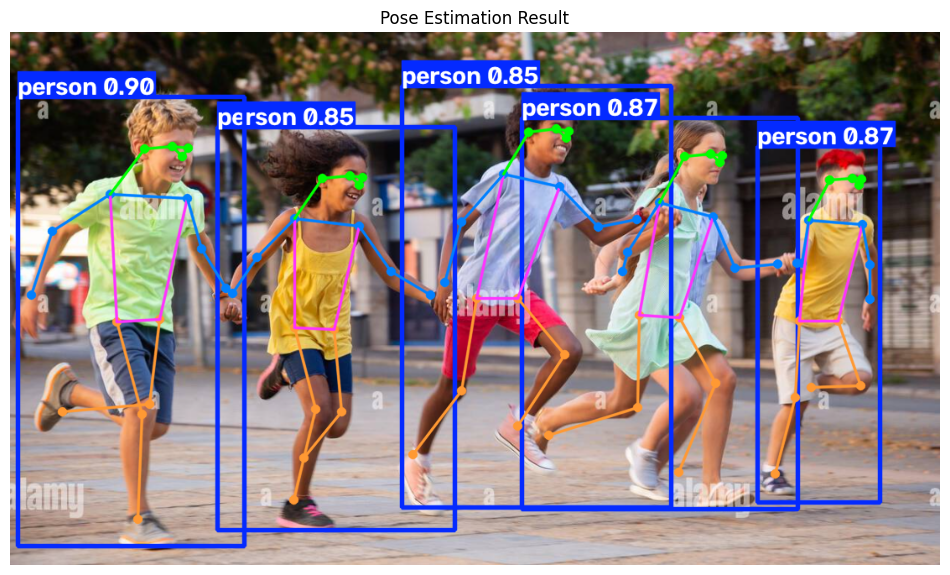

Successfully detected skeletons for 5 people!


In [1]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load the pose estimation model 
# (The '-pose' suffix indicates it is a keypoint detection model)
pose_model = YOLO("yolo_models/yolo26n-pose.pt")

# 2. Read the demo image
image = cv2.imread("images/demo_kids2.png")

if image is None:
    print("Error: Could not load 'demo.jpg'. Please check the file path.")
else:
    # 3. Run pose estimation
    # The model detects human bounding boxes AND calculates their skeletal keypoints
    results = pose_model(image)

    # 4. Use the built-in plot() method to draw bounding boxes and the pose skeleton
    processed_image = results[0].plot()

    # 5. Convert BGR (OpenCV) to RGB (Matplotlib) for correct colors
    processed_image_rgb = cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGB)

    # 6. Display the result
    plt.figure(figsize=(12, 8))
    plt.imshow(processed_image_rgb)
    plt.title('Pose Estimation Result')
    plt.axis('off')
    plt.show()

    # ---------------------------------------------------------
    # NATIVE EXTRACTION TIP FOR STUDENTS
    # The default COCO pose model predicts 17 standard human keypoints per person:
    # (Nose, Eyes, Ears, Shoulders, Elbows, Wrists, Hips, Knees, Ankles)
    if results[0].keypoints is not None:
        print(f"Successfully detected skeletons for {len(results[0].keypoints)} people!")
        
        # results[0].keypoints.xy gives the precise (X, Y) pixel coordinates for every joint
        # Example: to get the coordinates of the first person's nose (index 0)
        # nose_x, nose_y = results[0].keypoints.xy[0][0]
    else:
        print("No human keypoints were detected in this image.")